In [1]:
# load the data
import pandas as pd

cols = ['unit', 'cycle', 'op1', 'op2', 'op3'] + [f's{i}' for i in range(1, 22)]

train = pd.read_csv('train_FD001.txt', sep=r'\s+', header=None, names=cols)
test  = pd.read_csv('test_FD001.txt',  sep=r'\s+', header=None, names=cols)
rul   = pd.read_csv('RUL_FD001.txt', header=None, names=['RUL'])

# Target: remaining useful life for each training row
train['RUL'] = train.groupby('unit')['cycle'].transform('max') - train['cycle']

print(train.shape, test.shape, rul.shape)
train.head()




(20631, 27) (13096, 26) (100, 1)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [4]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# 1. Cap RUL at 125 (early in an engine's life, degradation isn't visible)
train['RUL'] = train['RUL'].clip(upper=125)

# 2. Remove constant sensors (they carry no information)
sensors = [f's{i}' for i in range(1, 22)]
const = [c for c in sensors if train[c].nunique() == 1]
print('Removed:', const)
features = [c for c in sensors if c not in const]

# 3. Scale (fit on train only, then apply to test)
scaler = MinMaxScaler().fit(train[features])
train[features] = scaler.transform(train[features])
test[features]  = scaler.transform(test[features])

# 4. Train the baseline
X, y = train[features], train['RUL']
rf = RandomForestRegressor(n_estimators=100, max_depth=12,
                           min_samples_leaf=5, n_jobs=-1, random_state=42)
rf.fit(X, y)

# 5. Evaluate: use only the LAST row of each test engine
last = test.groupby('unit').tail(1)
pred = rf.predict(last[features])
true = rul['RUL'].clip(upper=125).values

rmse = np.sqrt(mean_squared_error(true, pred))
print('Baseline RMSE:', round(rmse, 2))



Removed: ['s1', 's5', 's10', 's16', 's18', 's19']
Baseline RMSE: 17.29


# build the windows

In [5]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

WINDOW = 30
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(42); np.random.seed(42)

def make_train_windows(df, features, window):
    Xs, ys = [], []
    for _, g in df.groupby('unit'):
        data, r = g[features].values, g['RUL'].values
        for i in range(window, len(g) + 1):
            Xs.append(data[i-window:i])   # last 30 cycles
            ys.append(r[i-1])             # RUL at the end of the window
    return np.array(Xs, dtype=np.float32), np.array(ys, dtype=np.float32)

def make_test_windows(df, features, window):
    Xs = []
    for _, g in df.groupby('unit'):
        data = g[features].values
        if len(data) < window:            # pad short engines
            data = np.vstack([np.repeat(data[:1], window - len(data), axis=0), data])
        Xs.append(data[-window:])         # only the last window
    return np.array(Xs, dtype=np.float32)

X_train, y_train = make_train_windows(train, features, WINDOW)
X_test = make_test_windows(test, features, WINDOW)
print(X_train.shape, X_test.shape)   # (≈17731, 30, 15) and (100, 30, 15)

(17731, 30, 15) (100, 30, 15)


# model and training

In [6]:
class LSTMModel(nn.Module):
    def __init__(self, n_features, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=2,
                            batch_first=True, dropout=0.2)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)   # use the last time step

model = LSTMModel(len(features)).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

# Divide RUL by 125 so targets are in 0-1 (trains more stably)
ds = TensorDataset(torch.tensor(X_train), torch.tensor(y_train / 125.0))
loader = DataLoader(ds, batch_size=256, shuffle=True)

for epoch in range(30):
    model.train(); total = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward(); opt.step()
        total += loss.item() * len(xb)
    if (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch+1}: train RMSE ≈ {np.sqrt(total/len(ds))*125:.1f}')

Epoch 5: train RMSE ≈ 16.1
Epoch 10: train RMSE ≈ 14.8
Epoch 15: train RMSE ≈ 14.1
Epoch 20: train RMSE ≈ 13.9
Epoch 25: train RMSE ≈ 13.4
Epoch 30: train RMSE ≈ 13.3


# evaluate

In [7]:
model.eval()
with torch.no_grad():
    pred = model(torch.tensor(X_test).to(device)).cpu().numpy() * 125

true = rul['RUL'].clip(upper=125).values
lstm_rmse = np.sqrt(mean_squared_error(true, pred))
print('Baseline RMSE:', round(rmse, 2))
print('LSTM RMSE:    ', round(lstm_rmse, 2))

Baseline RMSE: 17.29
LSTM RMSE:     13.86


# evaluate and visualize

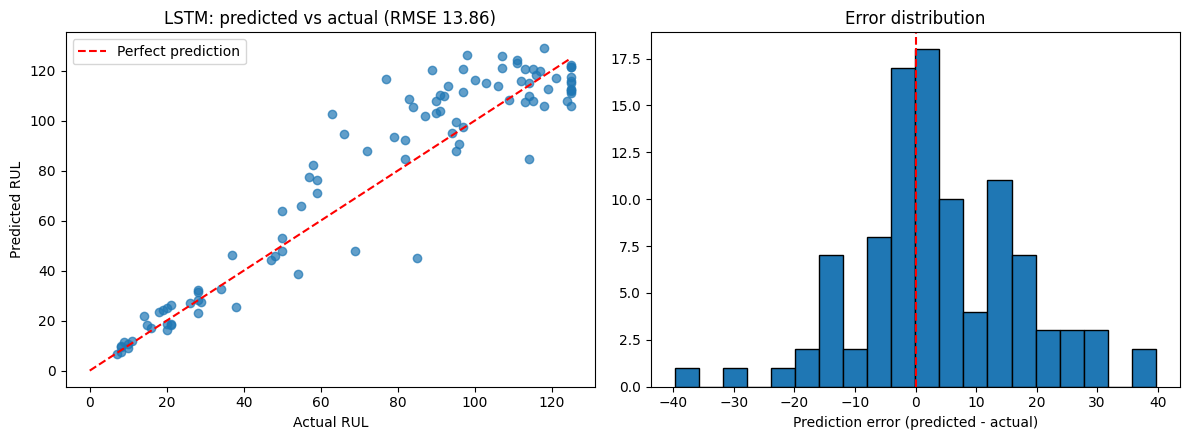

Worst 5 engines (test unit, actual, predicted):
93 85 45.2
79 63 102.7
67 77 116.7
86 89 120.3
45 114 84.7


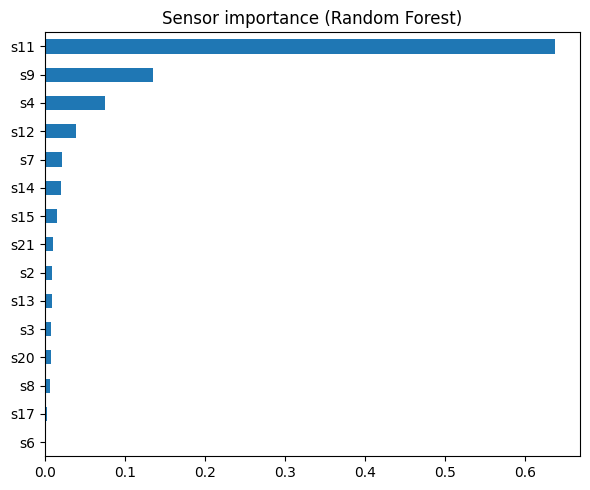

In [8]:
import matplotlib.pyplot as plt

# Plot 1: predicted vs actual RUL
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(true, pred, alpha=0.7)
ax[0].plot([0, 125], [0, 125], 'r--', label='Perfect prediction')
ax[0].set_xlabel('Actual RUL'); ax[0].set_ylabel('Predicted RUL')
ax[0].set_title(f'LSTM: predicted vs actual (RMSE {lstm_rmse:.2f})'); ax[0].legend()

# Plot 2: error distribution
errors = pred - true
ax[1].hist(errors, bins=20, edgecolor='black')
ax[1].axvline(0, color='r', linestyle='--')
ax[1].set_xlabel('Prediction error (predicted - actual)')
ax[1].set_title('Error distribution')
plt.tight_layout(); plt.savefig('results.png', dpi=150); plt.show()

# Where does the model make the biggest mistakes?
worst = np.argsort(-np.abs(errors))[:5]
print('Worst 5 engines (test unit, actual, predicted):')
for i in worst:
    print(i + 1, true[i], round(float(pred[i]), 1))

# Plot 3: which sensors matter most (from the Random Forest)
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind='barh', figsize=(6, 5), title='Sensor importance (Random Forest)')
plt.tight_layout(); plt.savefig('sensor_importance.png', dpi=150); plt.show()